# 像素腦 EP12｜黎曼猜想被 AI 證明了？
影片裡的數字都是這本筆記本跑出來的。黎曼猜想到現在（2026-11-22）還沒有被數學界確認證明；這裡做的是數值實驗，不是證明。

In [1]:
import json
import math

import numpy as np
from mpmath import mp, li, siegelz, zetazero

mp.dps = 20
R = {}

## 1. 質數越來越稀疏
用篩法數出一千萬以內的質數，看看比例怎麼變。

In [2]:
# 1. 質數越來越稀疏：埃拉托斯特尼篩法
N = 10_000_000
sieve = np.ones(N + 1, dtype=bool)
sieve[:2] = False
for i in range(2, int(N ** 0.5) + 1):
    if sieve[i]:
        sieve[i * i::i] = False
pi = np.cumsum(sieve)
R["pi"] = {str(10 ** k): int(pi[10 ** k]) for k in range(1, 8)}
R["density_pct"] = {str(10 ** k): round(100 * int(pi[10 ** k]) / 10 ** k, 2) for k in range(1, 8)}

## 2. 估計公式 li(x) 差多少
`li_vs_pi` 每一列是：真正的質數個數、li(x)、差多少、√x·log x。

In [3]:
# 2. 黎曼的估計 li(x) 和真正的質數個數差多少
R["li_vs_pi"] = {str(10 ** k): [int(pi[10 ** k]), round(float(li(10 ** k)), 1), round(float(li(10 ** k)) - int(pi[10 ** k]), 1),
                                round(math.sqrt(10 ** k) * math.log(10 ** k), 1)] for k in range(2, 8)}
# li(x) 是不是一直比 π(x) 大？（只查到一千萬）
xs = np.arange(2, N + 1, 1000)
R["li_always_bigger_up_to_1e7"] = bool(all(float(li(int(x))) > pi[int(x)] for x in xs))

## 3. ζ 函數的前幾個零點
注意：mpmath 的 `zetazero` 是在 1/2 那條線上找零點，所以「實部都是 1/2」不能拿來當證據；真正的檢查看下一格。

In [4]:
# 3. 前 10 個零點，實部都是 1/2
zs = [zetazero(n) for n in range(1, 101)]
R["zeros10"] = [[float(z.real), round(float(z.imag), 4)] for z in zs[:10]]
R["zeros100_all_half"] = all(z.real == 0.5 for z in zs)
R["zero100_height"] = round(float(zs[99].imag), 3)

## 4. 在 1/2 那條線上數零點
Z(t) 正負號換一次就是一個零點；再用黎曼–馮曼戈爾特公式算出這個高度以下應該有幾個。兩個一樣，代表這一段的零點都在線上。試試看把 `T` 改大（會跑比較久）。

In [5]:
# 4. 在 1/2 那條線上走：Z(t) 正負號換一次＝一個零點；跟「應該有幾個」比對
T = 100.0
ts = np.linspace(1, T, 20000)
Z = np.array([float(siegelz(t)) for t in ts])
sign_changes = int(np.sum(np.sign(Z[1:]) != np.sign(Z[:-1])))
theta_T = float(mp.siegeltheta(T))
N_T = theta_T / math.pi + 1 + float(mp.im(mp.log(mp.zeta(mp.mpf(0.5) + 1j * T))) / math.pi)  # 黎曼–馮曼戈爾特公式算出的個數
R["walk_T"] = T
R["sign_changes_on_line"] = sign_changes
R["N_T_formula"] = round(N_T, 3)
R["Z_curve"] = [[round(float(t), 2), round(float(z), 3)] for t, z in zip(ts[::100], Z[::100])]

## 5. 用零點把質數階梯彈回來
黎曼的明確公式（ψ(x) 的版本）：從平滑曲線開始，一對一對加進零點。改改看 `K` 的數量。

In [6]:
# 5. 用零點把質數「彈」回來：黎曼的明確公式（ψ(x) 版本，零點一對一對加）
x = np.linspace(2, 50, 1200)
def psi_from_zeros(K):
    y = x - math.log(2 * math.pi) - 0.5 * np.log(1 - x ** -2.0)
    for z in zs[:K]:
        g = float(z.imag)
        rho = complex(0.5, g)
        y -= 2 * np.real(np.exp(rho * np.log(x)) / rho)
    return y
def psi_true(xx):
    out = []
    for v in xx:
        s = 0.0
        for p in range(2, int(v) + 1):
            if sieve[p]:
                pk = p
                while pk <= v:
                    s += math.log(p)
                    pk *= p
        out.append(s)
    return np.array(out)
true = psi_true(x)
R["psi_x"] = [round(float(v), 3) for v in x[::6]]
R["psi_true"] = [round(float(v), 3) for v in true[::6]]
R["psi_err"] = {}
for K in (0, 3, 10, 100):
    y = psi_from_zeros(K)
    R["psi_" + str(K)] = [round(float(v), 3) for v in y[::6]]
    mask = np.abs(x - np.round(x)) > 0.15  # 避開跳的那一點
    R["psi_err"][str(K)] = round(float(np.mean(np.abs(y - true)[mask])), 3)

## 結果

In [7]:
for k in ("pi", "density_pct", "li_vs_pi", "sign_changes_on_line", "N_T_formula", "psi_err"):
    print(k, R[k])

pi {'10': 4, '100': 25, '1000': 168, '10000': 1229, '100000': 9592, '1000000': 78498, '10000000': 664579}
density_pct {'10': 40.0, '100': 25.0, '1000': 16.8, '10000': 12.29, '100000': 9.59, '1000000': 7.85, '10000000': 6.65}
li_vs_pi {'100': [25, 30.1, 5.1, 46.1], '1000': [168, 177.6, 9.6, 218.4], '10000': [1229, 1246.1, 17.1, 921.0], '100000': [9592, 9629.8, 37.8, 3640.7], '1000000': [78498, 78627.5, 129.5, 13815.5], '10000000': [664579, 664918.4, 339.4, 50969.9]}
sign_changes_on_line 29
N_T_formula 29.0
psi_err {'0': 0.849, '3': 0.614, '10': 0.456, '100': 0.129}


## 畫出來看看

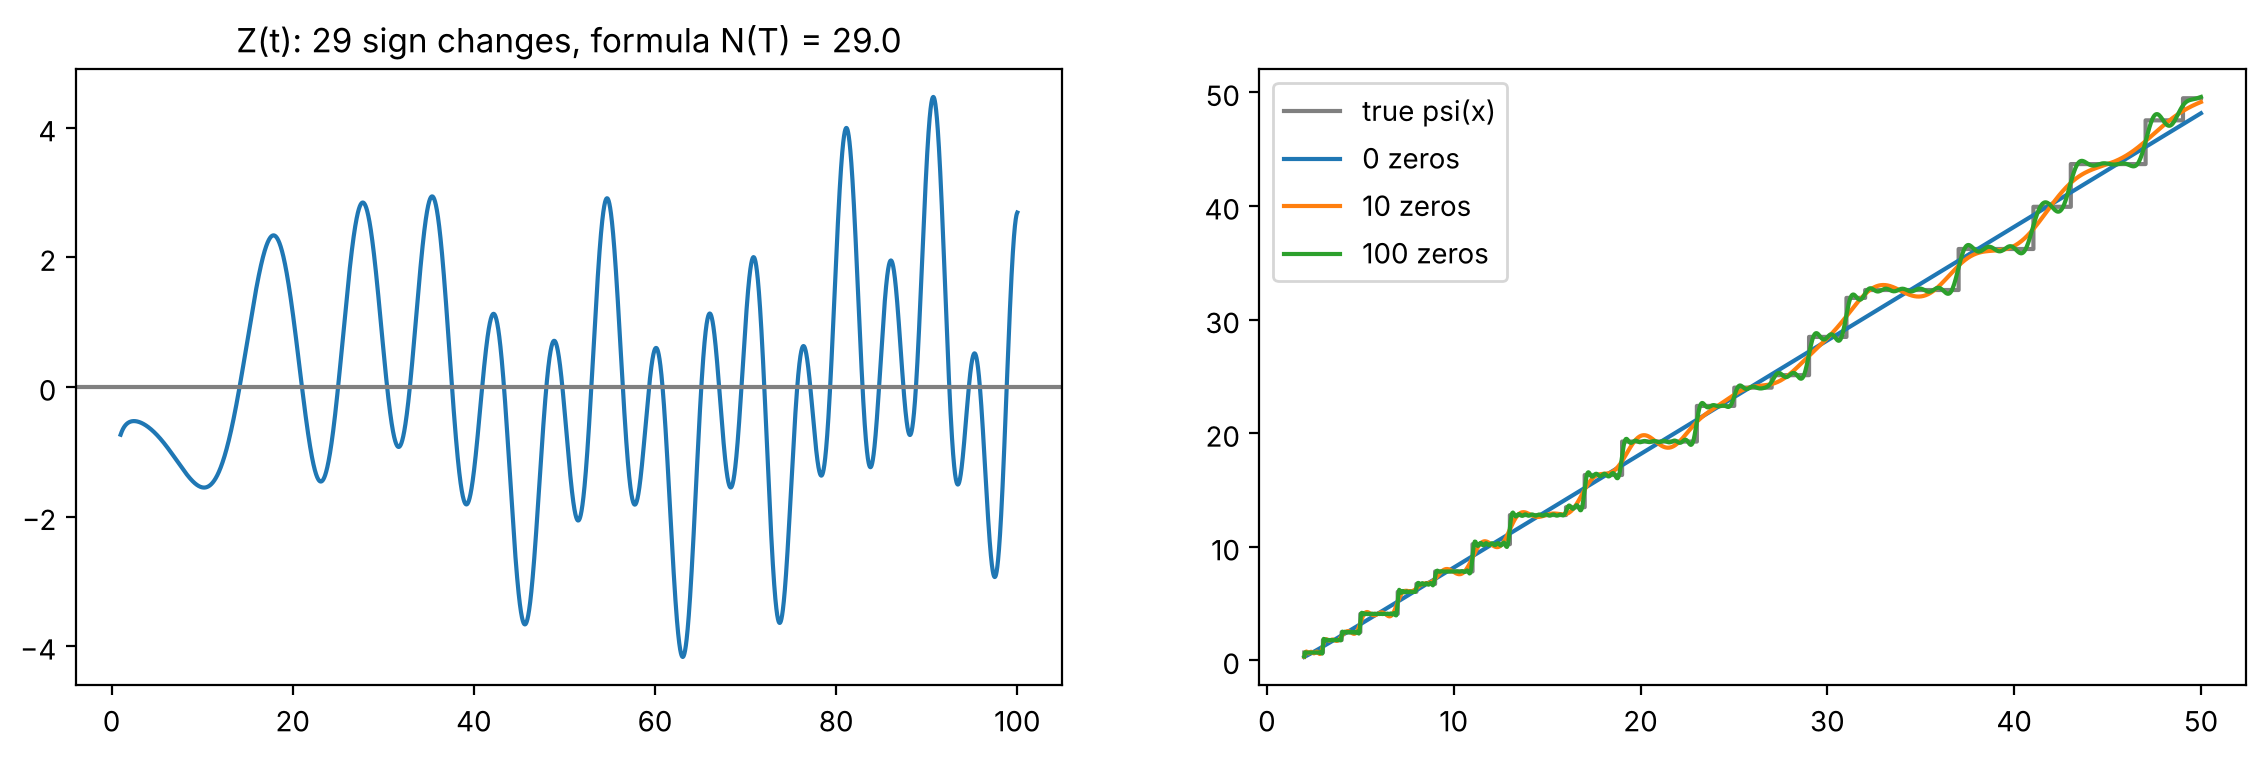

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(ts, Z); ax[0].axhline(0, color="gray"); ax[0].set_title(f"Z(t): {sign_changes} sign changes, formula N(T) = {N_T:.1f}")
ax[1].step(x, true, where="post", color="gray", label="true psi(x)")
for K in (0, 10, 100):
    ax[1].plot(x, psi_from_zeros(K), label=f"{K} zeros")
ax[1].legend(); plt.show()